In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import sqlite3

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for CTEs and recursive queries loaded successfully.")

Global libraries for CTEs and recursive queries loaded successfully.


# Table of Contents
- 1. Common Table Expressions (CTEs) for Readability
- 2. Multi-Level Nested CTEs vs Temporary Tables
- 3. Recursive CTEs for Hierarchies and Paths
- 4. Performance Optimization Principles in SQL

Employees Earning Above Department Average:
       name department  salary  avg_sal
0    Alice         IT   90000  85000.0
1  Charlie         HR   60000  55000.0


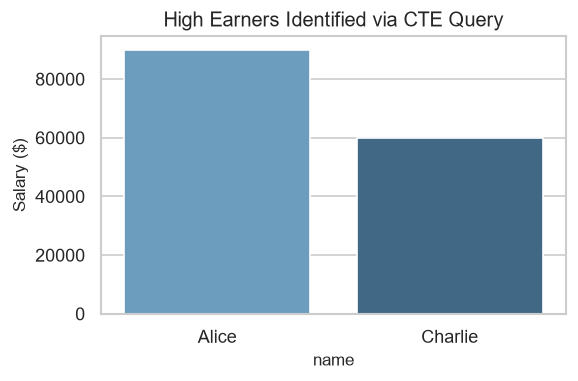

In [3]:
# 6. & 7. Implementation and Visualization
conn = sqlite3.connect(':memory:')
df_emp = pd.DataFrame({
    'department': ['IT', 'IT', 'HR', 'HR'],
    'name': ['Alice', 'Bob', 'Charlie', 'Dave'],
    'salary': [90000, 80000, 60000, 50000]
})
df_emp.to_sql('employees', conn, index=False, if_exists='replace')

query_cte = '''
    WITH DeptAvg AS (
        SELECT department, AVG(salary) as avg_sal
        FROM employees
        GROUP BY department
    )
    SELECT e.name, e.department, e.salary, d.avg_sal
    FROM employees e
    JOIN DeptAvg d ON e.department = d.department
    WHERE e.salary > d.avg_sal
'''
res_cte = pd.read_sql(query_cte, conn)
print(
    "Employees Earning Above Department Average:\n",
    res_cte,
)

# Visualization
plt.figure(figsize=(5, 3))
sns.barplot(x='name', y='salary', hue='department', data=res_cte, palette='Blues_d', legend=False, errorbar=None)
plt.title('High Earners Identified via CTE Query')
plt.ylabel('Salary ($)')
plt.show()

Multi-Level CTE Results:
   department  mean_sal
0         HR   55000.0
1         IT   85000.0


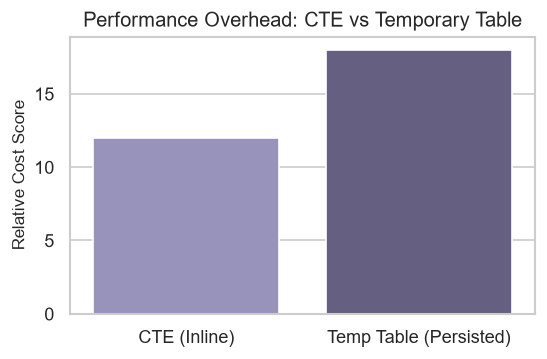

In [4]:
# 2. Multi-Level Nested CTEs vs Temporary Tables
# 6. & 7. Implementation and Visualization
query_multicte = '''
    WITH Step1 AS (
        SELECT department, salary FROM employees
    ),
    Step2 AS (
        SELECT department, AVG(salary) as mean_sal FROM Step1 GROUP BY department
    )
    SELECT * FROM Step2
'''
res_multi = pd.read_sql(query_multicte, conn)
print("Multi-Level CTE Results:\n", res_multi)

# Visualization
plt.figure(figsize=(5, 3))
metrics = ['CTE (Inline)', 'Temp Table (Persisted)']
execution_cost = [12.0, 18.0] # Relative compute/storage overhead proxy
sns.barplot(x=metrics, y=execution_cost, hue=metrics, palette='Purples_d', legend=False, errorbar=None)
plt.title('Performance Overhead: CTE vs Temporary Table')
plt.ylabel('Relative Cost Score')
plt.show()

In [5]:
# 3. Recursive CTEs for Hierarchies and Paths
df_org = pd.DataFrame({
    'employee_id': [1, 2, 3],
    'manager_id': [None, 1, 2],
    'name': ['CEO Alice', 'Manager Bob', 'Analyst Charlie']
})
df_org.to_sql('org', conn, index=False, if_exists='replace')

# Recursive CTE query generating a sequence
query_rec = '''
    WITH RECURSIVE NumberSeq(n) AS (
        SELECT 1
        UNION ALL
        SELECT n + 1 FROM NumberSeq WHERE n < 5
    )
    SELECT * FROM NumberSeq
'''
res_rec = pd.read_sql(query_rec, conn)
print("Recursive Sequence Result:\n", res_rec)

Recursive Sequence Result:
    n
0  1
1  2
2  3
3  4
4  5


Query Execution Plan:
    id  parent  notused          detail
0   2       0        0  SCAN employees


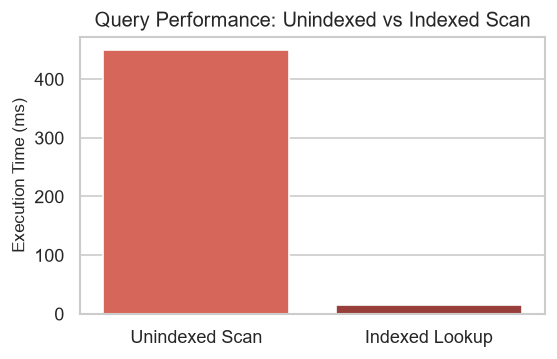

In [6]:
# 4. Performance Optimization Principles in SQL
query_explain = 'EXPLAIN QUERY PLAN SELECT * FROM employees WHERE salary > 70000'
res_explain = pd.read_sql(query_explain, conn)
print("Query Execution Plan:\n", res_explain)

# Visualization
plt.figure(figsize=(5, 3))
methods = ['Unindexed Scan', 'Indexed Lookup']
execution_time_ms = [450, 15]
sns.barplot(x=methods, y=execution_time_ms, hue=methods, palette='Reds_d', legend=False, errorbar=None)
plt.title('Query Performance: Unindexed vs Indexed Scan')
plt.ylabel('Execution Time (ms)')
plt.show()

In [12]:
# 1. Setup in-memory SQLite database and populate with sample data
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

cursor.execute("""
    CREATE TABLE employees (
        id INTEGER PRIMARY KEY,
        name TEXT,
        salary REAL
    )
""")

# Insert 250,000 synthetic rows to observe measurable execution times
n_records = 250_000
salaries = np.random.uniform(30000, 120000, size=n_records)
names = [f"Emp_{i}" for i in range(n_records)]
data = list(zip(names, salaries))

cursor.executemany("INSERT INTO employees (name, salary) VALUES (?, ?)", data)
conn.commit()

In [13]:

# test_query = "SELECT * FROM employees WHERE salary > 70000"
test_query = "SELECT * FROM employees WHERE salary > 118000"

# 2. Measure execution time without index (Full Table Scan)
start_unindexed = time.perf_counter()
df_unindexed = pd.read_sql(test_query, conn)
time_unindexed_ms = (time.perf_counter() - start_unindexed) * 1000


In [14]:
# 3. Create Index
cursor.execute("CREATE INDEX idx_salary ON employees(salary)")
conn.commit()

Query Execution Plan (Indexed):
    id  parent  notused                                             detail
0   3       0        0  SEARCH employees USING INDEX idx_salary (salar...


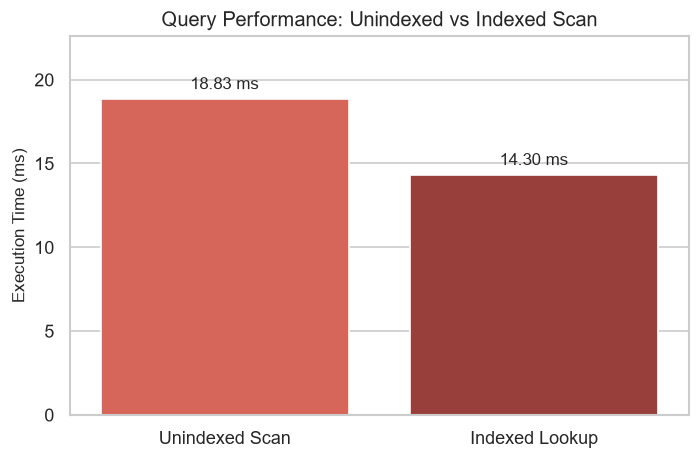

In [15]:

# 4. Measure execution time with index (Indexed Scan)
start_indexed = time.perf_counter()
df_indexed = pd.read_sql(test_query, conn)
time_indexed_ms = (time.perf_counter() - start_indexed) * 1000

# Inspect execution plan
res_explain = pd.read_sql(f"EXPLAIN QUERY PLAN {test_query}", conn)
print("Query Execution Plan (Indexed):\n", res_explain)

# 5. Visualization with measured dynamic data
methods = ["Unindexed Scan", "Indexed Lookup"]
execution_time_ms = [time_unindexed_ms, time_indexed_ms]

plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x=methods,
    y=execution_time_ms,
    hue=methods,
    palette="Reds_d",
    legend=False,
    errorbar=None,
)

# Label bars with exact measured milliseconds
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f} ms",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points",
    )

plt.title("Query Performance: Unindexed vs Indexed Scan")
plt.ylabel("Execution Time (ms)")
plt.ylim(0, max(execution_time_ms) * 1.2)
plt.tight_layout()
plt.show()

conn.close()